# Palette

> Generate gamut-checked OKLCH `light-dark()` neutral and vivid colour ladders, semantic tokens, and `nbs/palette.css` from `--hue` and `--neutral-hue`.

In [ ]:
#| hide
#| asset styles.css
_css = r'''
@layer reset, tokens, base, layout, components, app, utilities;
'''

## Design Rationale


Most design systems name colours by role (`primary`, `secondary`, `surface`, `outline`, `muted`, `destructive`) and hand-pick each swatch. Many roles need multiple shades (such as button fill, alert wash, and label), turning each role into a bundle of swatches. Every new state or theme (warning, dark mode) multiplies those bundles, leaving a hand-picked grid with no guarantee of completeness, consistency, or safe extension.

Instead, we build a generator that derives a complete colour family from a single hue. Each family is an ordinal ladder of prominence steps called rungs, where negative steps are less prominent and positive steps are more prominent. For example, step 0 is the solid fill, step +1 the hover state, and step -3 the page background. Attaching contrast or perceptual-separation targets to these rungs lets us compute every colour numerically rather than by eye.

AnswerUI uses two ladders. The vivid ladder defines accent colours (buttons, links, alert fills, and focus rings). The neutral ladder defines near-grey UI colours (page, surface, border, and text). By default the neutral ladder uses a cool blue hue (`260`), keeping surrounding text neutral when the accent hue changes. Set both `--hue` and `--neutral-hue` to the same value to tint a whole region together.

Computing rungs from stated targets lets us regenerate the palette whenever we change a contrast target, the number of rungs, or the neutral tint. The palette and generator have these requirements:

### Properties of the palette

- P1. Perceptual uniformity across hue: steps at the same prominence must look equally bright regardless of hue. A yellow solid and a blue solid at the same step should have the same visual weight, avoiding glowing buttons in some palettes and muted ones in others.
- P2. Step distinctness: adjacent steps on each ladder must remain perceptually separable at every hue so users can distinguish neighbouring component states.
- P3. Guaranteed contrast at every hue: contrast targets must hold across all hues, structured using [WCAG 2 ratios](https://www.w3.org/WAI/WCAG21/Understanding/contrast-minimum.html).
- P4. Hue interchangeability: any hue must produce a usable family without special cases or illegible, neon colours.
- P5. Dual-theme support: light and dark themes must belong to the same family and independently meet every uniformity and contrast requirement.
- P6. Context extensibility: adding a named context (danger, warning, success) requires only a hue value.


### Properties of the generator

- G1. Browser-native derivation: the browser computes colours from the hue at runtime without pre-computed colour tables or JavaScript.
- G2. Gamut-aware: chroma at each step stays inside the sRGB gamut boundary for that lightness and hue, preventing silent browser clamping to unverified colours.
- G3. Contrast-derived anchors: ladder steps with WCAG obligations (such as text on a primary button) are computed from contrast targets (P3) rather than chosen by eye. Steps without contrast obligations (backgrounds, interaction states) are spaced mechanically between anchored steps.
- G4. Mechanical inputs: changing the number of steps requires adjusting minimal parameters while preserving aesthetic and functional consistency.
- G5. Machine-verified: code checks gamut containment, contrast ratios, and adjacent-step distinctness, and verifies the generated CSS against those checks.

## Utilities


To build and verify the palette, we need utilities for OKLCH-to-sRGB conversion, WCAG relative luminance, and side-by-side colour swatches.

In [ ]:
import numpy as np, matplotlib.pyplot as plt, pandas as pd
from fasthtml.common import Div
from fastcore.test import *
from scipy.optimize import brentq
from nbdev.config import get_config
from textwrap import indent

In [ ]:
%config InlineBackend.figure_format = 'retina'
plt.rcParams['figure.dpi'] = 75

### OKLCH to sRGB


OKLCH represents a colour with three values: `L` for perceived lightness (0 to 1), `C` for chroma (colourfulness), and `h` for hue in degrees. It is the polar form of Oklab, published by [Björn Ottosson](https://bottosson.github.io/) in 2020 as a successor to CIELAB. Equal `L` gives equal perceived brightness across hue and chroma (P1). Equal steps in `L` produce uniform visual steps (P2). CSS supports `oklch()` natively.

Displaying or measuring a colour requires sRGB. Below we implement [Ottosson's conversion](https://bottosson.github.io/posts/oklab/) in both linear and gamma-encoded sRGB. WCAG contrast (P3) uses linear luminance, while hex swatches (P1, P2) use gamma-encoded sRGB.

In [ ]:
M1 = np.array([[0.4122214708, 0.5363325363, 0.0514459929],
               [0.2119034982, 0.6806995451, 0.1073969566],
               [0.0883024619, 0.2817188376, 0.6299787005]])
M2 = np.array([[0.2104542553,  0.7936177850, -0.0040720468],
               [1.9779984951, -2.4285922050,  0.4505937099],
               [0.0259040371,  0.7827717662, -0.8086757660]])
M1i, M2i = np.linalg.inv(M1), np.linalg.inv(M2)

def oklch2lin(L, C, h):
    "Linear sRGB (unclamped) for oklch `L`, `C`, hue `h` in degrees"
    hr = np.deg2rad(h)
    lab = np.stack(np.broadcast_arrays(L, C*np.cos(hr), C*np.sin(hr)), axis=-1)
    return ((lab @ M2i.T)**3) @ M1i.T

def lin2srgb(lin): return np.where(lin <= .0031308, 12.92*lin, 1.055*np.abs(lin)**(1/2.4) - .055)
def rgb2hex(rgb): return '#%02x%02x%02x' % tuple(round(c*255) for c in np.clip(rgb, 0, 1))
def oklch2hex(L, C, h): return rgb2hex(lin2srgb(oklch2lin(L, C, h)))

We validate the conversion against two known colours: white (`L=1, C=0`) and sRGB pure red from [MDN](https://developer.mozilla.org/en-US/docs/Web/CSS/color_value/oklch).

In [ ]:
test_close(oklch2lin(1, 0, 0), [1, 1, 1], eps=1e-5)
test_close(lin2srgb(oklch2lin(.62796, .25768, 29.234)), [1, 0, 0], eps=1e-3)

### Luminance and contrast


WCAG defines readability as the ratio of relative luminances between two colours:

\[
\frac{Y_{\text{light}} + 0.05}{Y_{\text{dark}} + 0.05}
\]

Here \(Y\) is the light a colour emits, weighted by human sensitivity to each primary according to the [WCAG relative luminance formula](https://www.w3.org/WAI/GL/wiki/Relative_luminance#Definition_as_Stated_in_WCAG_2.x):

\[
Y = 0.2126\,R + 0.7152\,G + 0.0722\,B
\]

The targets are 4.5:1 for normal text and 3:1 for large text and UI components (P3).

Because standard sRGB values are gamma-encoded rather than linear light, we undo the gamma curve first and then apply the luminance weights to compute `Y`.

In [ ]:
LUM = np.array([.2126, .7152, .0722])

def srgb2lin(rgb):
    "Undo sRGB gamma: the light actually emitted per channel, 0–1"
    rgb = np.asarray(rgb)
    return np.where(rgb <= .04045, rgb/12.92, ((rgb+.055)/1.055)**2.4)

def srgb2lum(rgb):
    "WCAG relative luminance of sRGB `rgb`, components 0–1"
    return srgb2lin(rgb) @ LUM

def oklch2lum(L, C, h):
    "WCAG relative luminance of an oklch colour"
    return oklch2lin(L, C, h) @ LUM

def hex2rgb(c): return np.array([int(c[i:i+2], 16)/255 for i in (1,3,5)])

def contrast(y1, y2):
    "WCAG contrast ratio between two relative luminances"
    lo, hi = np.minimum(y1, y2), np.maximum(y1, y2)
    return (hi + .05) / (lo + .05)

As a boundary check, [WebAIM](https://webaim.org/articles/contrast/) cites mid-grey `#767676` on white as the lightest 8-bit grey that passes the 4.5:1 AA threshold. Its WCAG contrast ratio is 4.54:1.

In [ ]:
test_close(contrast(srgb2lum(hex2rgb('#767676')), 1.), 4.54, eps=.01)

The luminance of `#ff0000` (pure red) should match the luminance calculated from its oklch value:

In [ ]:
test_close(oklch2lum(.62796, .25768, 29.234), srgb2lum(hex2rgb('#ff0000')), eps=1e-3)

### Swatches



A row of colour chips with captions, for visual comparison of candidates.

In [ ]:
def swatch(c, lbl=''):
    return Div(Div(style=f'background:{c};height:3rem;border-radius:4px'),
               Div(lbl, style='font-size:0.7rem;text-align:center'), style='flex:1')

def swatches(cs, lbls=None): return Div(*[swatch(c,l) for c,l in zip(cs, lbls or cs)], style='display:flex;gap:4px')

Motivating demo: a hue sweep at constant HSL "lightness" versus one at constant oklch `L`.

In [ ]:
hs12 = range(0, 360, 30)
swatches([f'hsl({h} 100% 50%)' for h in hs12], [f'{h}°' for h in hs12])

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:hsl(0 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:hsl(30 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:hsl(60 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:hsl(90 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:hsl(120 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:hsl(150 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:hsl(180 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:hsl(210 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:hsl(240 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:hsl(270 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:hsl(300 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:hsl(330 100% 50%);height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

At HSL lightness 50%, perceived brightness varies sharply across hues. Yellow and cyan glow while blue recedes.

In [ ]:
swatches([oklch2hex(.6, .15, h) for h in hs12], [f'{h}°' for h in hs12])

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#c5547c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#ca5747;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#bf6600;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#a37a00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#768c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#25984d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#009c84;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#0096b1;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#0089d0;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#5e78d9;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#8f68cb;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#b05baa;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

The OKLCH row has uniform perceived brightness across hues, matching P1.

## Gamut Boundary


The sRGB gamut is small. At any lightness and hue, the maximum displayable chroma varies jaggedly with both. To avoid silent browser clamping (G2), we compute gamut membership directly.

In [ ]:
def in_gamut(L, C, h, eps=1e-4):
    "True where oklch (`L`,`C`,`h`) lies inside sRGB: every linear channel in [0,1]"
    lin = oklch2lin(L, C, h)
    return ((lin > -eps) & (lin < 1+eps)).all(-1)

In [ ]:
assert in_gamut(.62796, .25768, 29.234)         # pure red: on the boundary, inside
assert not in_gamut(.62796, .27,    29.234)     # a nudge more chroma: outside
assert in_gamut(1, 0, 0) and in_gamut(0, 0, 0)  # the achromatic poles

We find the maximum displayable chroma `cmax(L, h)` by bisection. The upper bracket `0.5` sits above sRGB's global chroma maximum (about `0.32` near the blue primary).

In [ ]:
def cmax(L, h, tol=1e-5):
    "Largest displayable chroma at lightness `L`, hue `h`"
    L, h = np.broadcast_arrays(np.asarray(L, float), np.asarray(h, float))
    lo, hi = np.zeros_like(L), np.full_like(L, .5)
    while (hi-lo).max() > tol:
        mid = (lo+hi)/2
        ok = in_gamut(L, mid, h)
        lo, hi = np.where(ok, mid, lo), np.where(ok, hi, mid)
    return lo

In [ ]:
test_close(cmax(.62796, 29.234), .25768, eps=1e-3)
assert cmax(1, 180) < 1e-3

Plot `cmax` for all hues across six lightness slices (line colours are arbitrary):

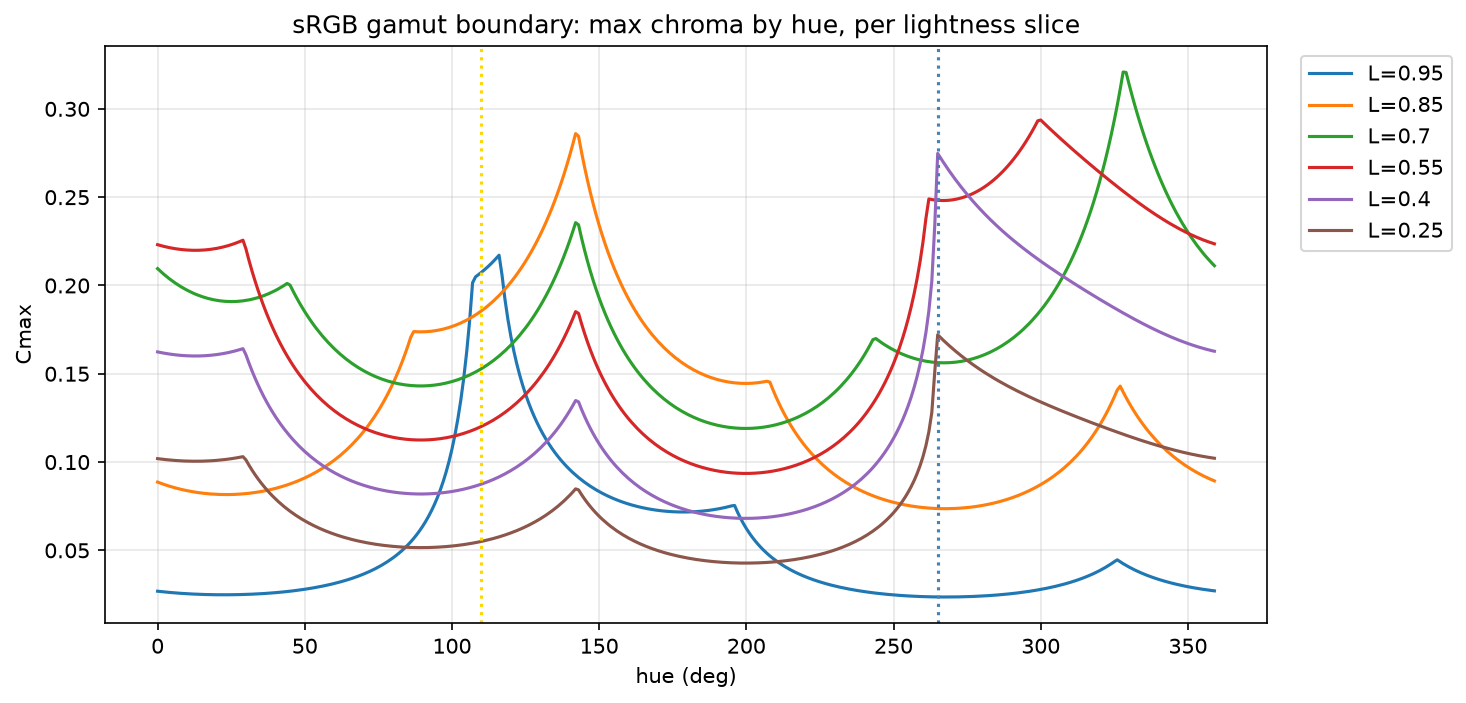

In [ ]:
hs = np.arange(360)
fig, ax = plt.subplots(figsize=(10, 5))
for L in (.95, .85, .70, .55, .40, .25): ax.plot(hs, cmax(L, hs), label=f'L={L}')
for h, c in [(110, 'gold'), (265, 'steelblue')]: ax.axvline(h, ls=':', lw=1.5, color=c)
ax.set(xlabel='hue (deg)', ylabel='Cmax', title='sRGB gamut boundary: max chroma by hue, per lightness slice')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1)); ax.grid(True, alpha=.3)

The boundary curve has sharp cusps near the sRGB primaries and secondaries, with a shape that varies by lightness. Yellow (`110°`, gold dotted line) reaches high chroma at high `L` and low chroma at low `L`, while blue (`265°`, blue dotted line) does the opposite.

In [ ]:
for L in (.85, .55, .25):
    print(f'L={L}')
    display(swatches([oklch2hex(L, c, h) for c,h in zip(cmax(L, hs12), hs12)], [f'{h}°' for h in hs12]))

L=0.85


<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#ffb6cb;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#ffbaae;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#ffbe8a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#fac700;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#bedf00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#00f674;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#00eed2;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#37e6ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#9cd6ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#bbccff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#d6c1ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#ffadf7;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

L=0.55


<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#cd006c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#d40f00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#a75c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#8b6e00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#687c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#00893d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#008474;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#008090;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#0079b3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#4056ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#9200fe;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#ba00b4;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

L=0.25


<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#440020;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#470100;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#361900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#2b2000;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#1e2500;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#002a0e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#002922;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00272d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#00243a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#0f006e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#2e0056;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#3d003b;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

### Vivid chroma


The boundary swatches show that maximum chroma is a physical limit rather than an aesthetic target. At medium lightness all hues look balanced. At high lightness (used for background washes) some hues look garish, while at low lightness blue stands out more than every other hue.

Capping every hue to the narrowest gamut eliminates the garish washes, at the cost of muddy colours at medium lightness. Instead, we use a chroma ceiling that tapers near black and white and peaks at medium lightness.

A simple candidate is a quadratic in lightness: zero at `L=0` and `L=1`, peaking at `L=0.5`.

In [ ]:
def ctarget(L, peak=.2):
    "Chroma ceiling: zero at the poles, `peak` at L=.5"
    return peak * 4*L*(1-L)

def palette_c(L, h, peak=.2):
    return np.minimum(ctarget(L, peak), cmax(L, h))

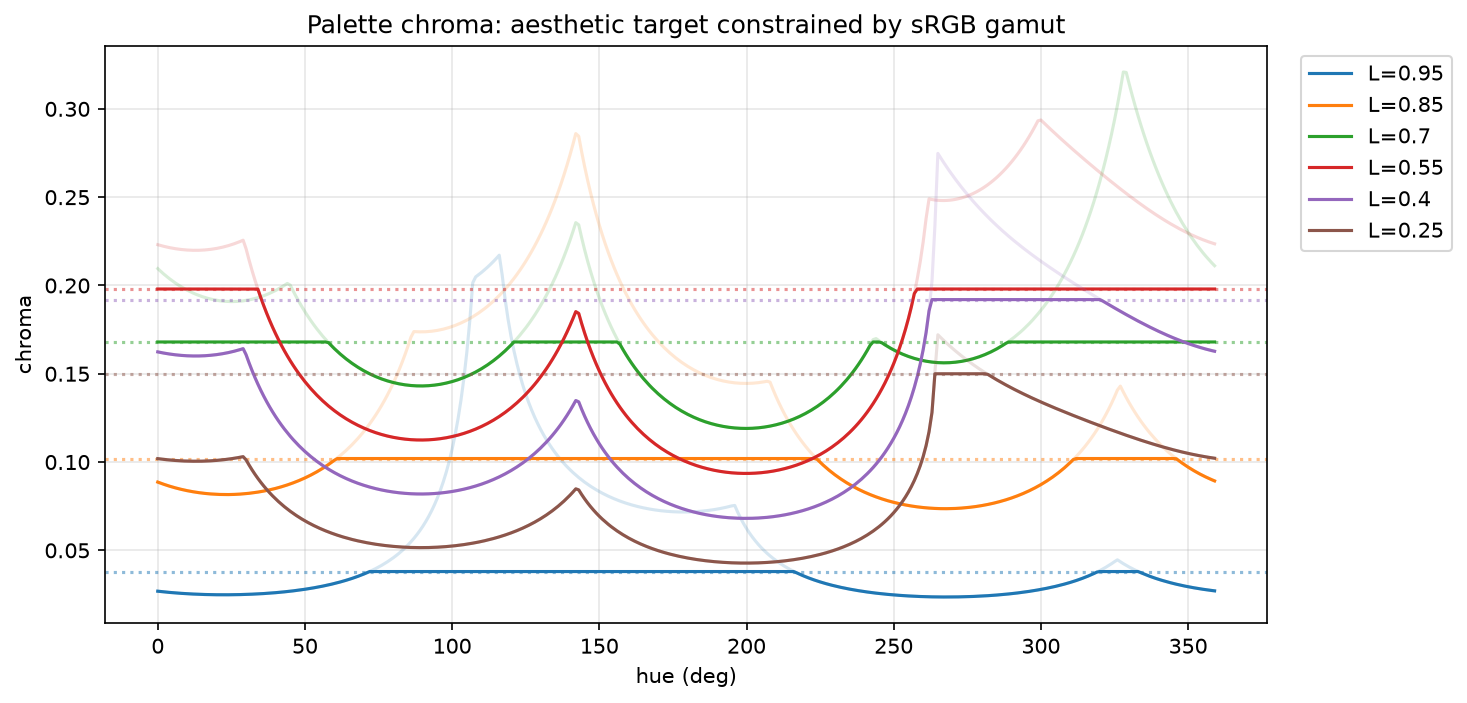

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

for L in (.95, .85, .70, .55, .40, .25):
    line, = ax.plot(hs, palette_c(L, hs), label=f'L={L}')
    clr = line.get_color()
    ax.plot(hs, cmax(L, hs), color=clr, alpha=.18)
    ax.axhline(ctarget(L), color=clr, ls=':', alpha=.5)

ax.set(
    xlabel='hue (deg)', ylabel='chroma',
    title='Palette chroma: aesthetic target constrained by sRGB gamut')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
ax.grid(True, alpha=.3)

In [ ]:
for L in (.95, .85, .70, .55, .40, .25):
    display(swatches(
        [oklch2hex(L, palette_c(L, h), h) for h in hs12],
        [f'{h}°' for h in hs12]))

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#ffe7ee;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#ffe9e5;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#ffeada;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#f8eed2;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#ebf3d7;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#ddf6e1;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#d4f7ef;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#d2f6fd;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#dff1ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#e8eeff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#f1ebff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#fee6fb;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#ffb6cb;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#ffbaae;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#ffbe8a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#e8cb7e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#c5d88b;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#9de1ab;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#7ce4d0;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#75e0f3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#9cd6ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#bbccff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#d6c1ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#f4b6ee;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#ef6b9a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#f56f5c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#e68100;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#c19900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#92ac00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#3aba63;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#00b8a1;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00b2c8;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#00a9f7;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#7997ff;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#af83f6;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#d773cf;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#c5276d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#cc2b1c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#a75c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#8b6e00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#687c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#00893d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#008474;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#008090;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#0079b3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#4761e3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#864bd1;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#ad37a7;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#850044;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#8a0600;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#6b3900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#594500;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#414e00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#005724;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#005449;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00515c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#004d74;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#2632ac;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#5b189d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#780075;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#440020;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#470100;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#361900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#2b2000;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#1e2500;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#002a0e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#002922;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00272d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#00243a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#0e0967;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#2e0056;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#3d003b;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

The quadratic lowers chroma at high lightness while the sRGB gamut caps most dark colours, though the lightest rows still look slightly pastel. Adding a `shape` exponent narrows the curve near the poles without changing the peak at `L=0.5`.

In [ ]:
def ctarget(L, peak=.2, shape=1.):
    "Chroma ceiling: zero at the poles, `peak` at L=.5; `shape` above 1 lowers it everywhere else"
    return peak * (4*L*(1-L))**shape

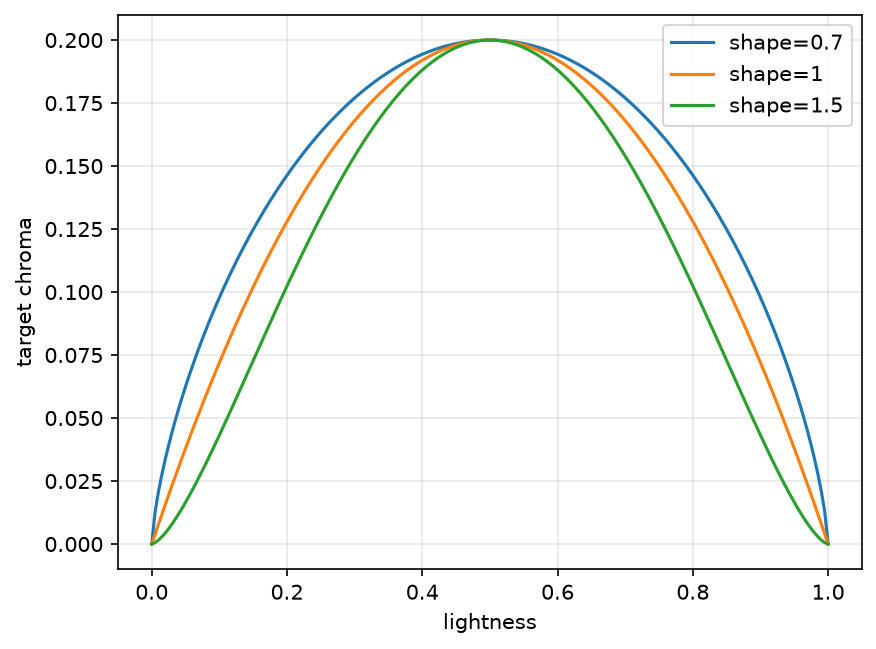

In [ ]:
Ls = np.linspace(0, 1, 200)
for shape in (.7, 1, 1.5):
    plt.plot(Ls, ctarget(Ls, shape=shape), label=f'{shape=}')
plt.xlabel('lightness'); plt.ylabel('target chroma')
plt.legend(); plt.grid(alpha=.3)

In [ ]:
def palette_c(L, h, peak=.2, shape=1.5):
    return np.minimum(ctarget(L, peak, shape), cmax(L, h))

In [ ]:
for L in (.95, .85, .70, .55, .40, .25):
    display(swatches(
        [oklch2hex(L, palette_c(L, h), h) for h in hs12],
        [f'{h}°' for h in hs12]))

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#f9eaee;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#f9ebe8;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#f7ece4;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#f3eee2;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#edf0e4;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#e7f2e9;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#e3f2ef;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#e3f2f5;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#e5f0f9;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#eaeefa;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#f0ecf8;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#f5ebf4;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#f7bacc;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#fabdb2;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#f2c39e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#e0cc97;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#c7d5a0;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#acdcb5;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#98decf;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#94dbe8;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#a3d5f9;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#bbccfe;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#d5c4f7;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#eabde5;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#e9719a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#ef7563;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#e28421;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#c19900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#93ab25;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#48b869;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#00b8a1;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00b2c8;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#1ca9f3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#7a97fe;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#ae86ef;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#d378cb;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#c4286d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#cb2c1d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#a75c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#8b6e00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#687c00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#00893d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#008474;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#008090;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#0079b3;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#4862e2;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#864bd1;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#ad38a7;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#850044;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#8a0600;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#6b3900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#594500;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#414e00;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#005724;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#005449;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00515c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#004d74;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#2633aa;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#5a1b9b;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#780075;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#440020;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#470100;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#361900;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#2b2000;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#1e2500;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#002a0e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#002922;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#00272d;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#00243a;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#0e125e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#2d0255;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#3d003b;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

Setting `shape=1.5` trims chroma in the pale and dark rows without altering the mid-lightness solids. The `L=.95` row now looks like gently tinted surfaces rather than pastel accents. We adopt `peak=.2` and `shape=1.5`.

### Neutral chroma


Vivid rungs need strong colour without looking garish. Neutral rungs should remain neutral while keeping enough of the neutral hue to tint surfaces and text.

Oklab uses three axes: perceived lightness \(L\), green-to-red \(a\), and blue-to-yellow \(b\). OKLCH is its polar form with chroma \(C\) and hue \(h\) in place of \(a\) and \(b\).

Oklab defines a perceptual colour-difference metric \(\Delta E_{\mathrm{OK}}\) for how different two colours look:

\[
\Delta E_{\mathrm{OK}} = \sqrt{\Delta L^2 + \Delta a^2 + \Delta b^2}
\]

Between an achromatic colour \((L, 0, h)\) and a chromatic colour at the same lightness and hue, \(\Delta L = 0\) and the combined difference in \(a\) and \(b\) equals \(C\):

\[
\Delta E_{\mathrm{OK}} = C
\]

Chroma is therefore the perceptual distance from grey in Oklab units. CSS Color 4 (§14.2.1) defines one just-noticeable difference (JND) as \(\Delta E_{\mathrm{OK}} = 0.02\). A neutral colour with \(C = 0.02\) is barely distinguishable from pure grey. See [Binary Search Gamut Mapping](https://www.w3.org/TR/css-color-4/#binsearch-gamut-mapping).

In [ ]:
JND = .02
L = .7
swatches([oklch2hex(L, np.minimum(JND, cmax(L, h)), h) for h in hs12], [f'{h}°' for h in hs12])

<div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#aa9a9e;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">0°</div></div><div style="flex:1"><div style="background:#ab9a97;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">30°</div></div><div style="flex:1"><div style="background:#a89c92;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">60°</div></div><div style="flex:1"><div style="background:#a39e91;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">90°</div></div><div style="flex:1"><div style="background:#9da093;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">120°</div></div><div style="flex:1"><div style="background:#96a298;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">150°</div></div><div style="flex:1"><div style="background:#92a39f;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">180°</div></div><div style="flex:1"><div style="background:#91a2a5;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">210°</div></div><div style="flex:1"><div style="background:#94a0aa;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">240°</div></div><div style="flex:1"><div style="background:#999eab;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">270°</div></div><div style="flex:1"><div style="background:#a09ca9;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">300°</div></div><div style="flex:1"><div style="background:#a69aa4;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">330°</div></div></div>

## Ladder Design


Here we choose the steps for each ladder and assign their targets. Next we solve for the lightness of each step from those targets.

### Parameters



We initialise a `params` dict to hold the tunable aesthetic parameters:

In [ ]:
params = dict(
    vivid_peak=.2, vivid_shape=1.5,  # aesthetic chroma ceiling
    neutral_tint=1,                  # neutral tint, in JNDs from grey
)

def vivid_ceil(L): return ctarget(L, params['vivid_peak'], params['vivid_shape'])
def neutral_ceil(L): return params['neutral_tint']*JND
def capped(ceil, L, h): return np.minimum(ceil(L), cmax(L, h))

### Base/page colour


The least-prominent rung (`n-3`) sets the default page background. App backgrounds sit near white or black rather than at pure extremes. Choosing `pole_contrast = 1.02` keeps the page background close enough to white or black while still allowing a visible tint.

In [ ]:
params['pole_contrast'] = 1.02

For pure grey (`C=0`) in OKLCH, relative luminance is \(Y = L^3\). Solving the WCAG contrast formula against white (\(Y = 1\)) and black (\(Y = 0\)) gives:

In [ ]:
base = dict(
    light=np.cbrt(1.05/params['pole_contrast'] - .05),
    dark=np.cbrt(.05*(params['pole_contrast'] - 1)))
base

{'light': np.float64(0.993089611430119),
 'dark': np.float64(0.10000000000000003)}

With one JND of tint in the neutral ladder, luminance and contrast vary slightly with hue. We find the hue that yields the lowest contrast against the pole.

In [ ]:
hgrid = np.arange(360)

def worst_pole_contrast(L, mode):
    "Lowest contrast between the neutral base at lightness `L` and its pole (white in light `mode`, black in dark), and the hue where it occurs"
    pole = 1 if mode == 'light' else 0
    ys = oklch2lum(L, capped(neutral_ceil, L, hgrid), hgrid)
    cs = contrast(ys, pole)
    i = np.argmin(cs)
    return cs[i], hgrid[i]

In [ ]:
for mode, L in base.items():
    c, h = worst_pole_contrast(L, mode)
    print(f'{mode:5}  L={L:.4f}  worst={c:.3f}:1  (hue {h}°)')

light  L=0.9931  worst=1.016:1  (hue 119°)
dark   L=0.1000  worst=1.018:1  (hue 352°)


Once tint is added, the lightness solved for achromatic colours falls short of `pole_contrast`. We therefore solve numerically for the lightness at which the worst sampled hue reaches `pole_contrast`.

In [ ]:
def solve_L(f, target, a=0, b=1):
    "Lightness between `a` and `b` where scalar function `f(L)` equals `target`"
    return brentq(lambda L: f(L) - target, *sorted((a, b)))

base = {mode: solve_L(lambda L: worst_pole_contrast(L, mode)[0], params['pole_contrast']) for mode in ('light', 'dark')}
base

{'light': 0.9914187710001124, 'dark': 0.10260423413702986}

With tint, the light base is slightly darker and the dark base slightly lighter.

In [ ]:
for mode, L in base.items():
    c, _ = worst_pole_contrast(L, mode)
    test_close(c, params['pole_contrast'], eps=1e-8)
    assert in_gamut(L, capped(neutral_ceil, L, hgrid), hgrid).all() 
    print(f'{mode:5} JNDs={(abs(L - (1 if mode == 'light' else 0)) / JND):.1f}')

light JNDs=0.4
dark  JNDs=5.1


A single `pole_contrast` is asymmetric in JND units: about `0.5` JND from white, but `5` JNDs from black. The `+0.05` flare term in the WCAG contrast formula models ambient light scattering, which masks small luminance steps near black far more than near white. Under normal viewing, using the same contrast ratio makes both page backgrounds look equally close to their poles despite the different JND distances.

### Ladder jobs


[Radix Colors](https://www.radix-ui.com/colors/docs/palette-composition/understanding-the-scale) defines a twelve-step scale covering app and subtle backgrounds (1-2), component backgrounds and hover/selected states (3-5), borders and focus rings (6-8), solid fills (9-10), and text (11-12).

AnswerUI splits those twelve roles across two six-step signed ladders. The neutral ladder (`n-3` through `n2`) provides page, surface, border, and ordinary text colours. The vivid ladder (`v-3` through `v2`) provides washes, rings, solid fills, and accent text.

Unlike Radix's hand-tuned swatches, we assign each role to a rung as a job with a measurable target.

We measure targets with two units. Contrast measures text legibility from luminance alone. Distinguishing a raised surface or wash from the page depends on perceptible difference (including tint) rather than legibility. For those rungs we require `sep = 2` JNDs in \(\Delta E_{\mathrm{OK}}\). A wash only `1` JND from a card is barely visible.

In [ ]:
params['sep'] = 2

In [ ]:
def job(desc, c=None, bg='n-3', d=None):
    "A rung use: contrast `c` (or a light/dark pair) or ΔEOK `d`, measured against `bg`"
    return dict(desc=desc, c=c, bg=bg, d=d)

def contrast_target(job, mode):
    c = job['c']
    return c[mode == 'dark'] if isinstance(c, tuple) else c

def ladder(ceil, rungs):
    "A family of rungs sharing the aesthetic ceiling `ceil(L)`: each rung name mapped to its jobs and ceiling"
    return {nm: dict(jobs=js if isinstance(js, tuple) else (js,), ceil=ceil) for nm, js in rungs.items()}

The neutral ladder uses near-zero chroma (`neutral_ceil`). Its first rung (`n-3`) is the page background derived from `pole_contrast`. Every other rung is placed relative to it.


In [ ]:
neutral = ladder(neutral_ceil, {
    'n-3': job('base: the lightness extreme (the default page)'),
    'n-2': job('raised surface: cards, inputs', d=params['sep']),
    'n-1': job('hairline borders, separators'),
    'n':   job('disabled text and controls'),
    'n1':  job('muted and placeholder text', c=4.5, bg='n-2'),
    'n2':  (job('body text', c=(7, 10)), job('body text on surface', c=(7, 10), bg='n-2')),
})

The vivid ladder defines the accent colours (`v-3` through `v2`).

In [ ]:
vivid = ladder(vivid_ceil, {
    'v-3': (job('subtle background wash', d=params['sep']), job('distinct from raised surface', d=params['sep'], bg='n-2')),
    'v-2': job('wash hover, selected'),
    'v-1': (job('border, focus ring', c=3, bg='n-2'), job('large accent text', c=3)),
    'v':   (job('solid fill with base-coloured label', c=(4.5, 7)), job('accent text on surface', c=(4.5, 7), bg='n-2')),
    'v1':  job('solid hover'),
    'v2':  (job('strong accent text on surface', c=(7, 10), bg='n-2'), job('alert text on wash', c=4.5, bg='v-3')),
})
rungs = neutral | vivid

The solver sets the lightness of each rung that has explicit targets (called pinned rungs) so its targets hold at every hue. Unpinned rungs are spaced geometrically in contrast between their pinned neighbours.

## Ladder Optimisation



With the bases fixed, we can generalize the same calculation to any pair of ladder rungs.

In [ ]:
def worst_contrast(L1, C1, L2, C2):
    "Lowest contrast between two rungs over every pair of context hues, one hue for each rung"
    y1, y2 = oklch2lum(L1, C1, hgrid), oklch2lum(L2, C2, hgrid)
    return contrast(y1[:,None], y2[None,:]).min()

def worst_sep(L1, C1, L2, C2):
    "Lowest same-hue ΔEOK between two rungs, in JNDs"
    return np.sqrt((L1-L2)**2 + (C1-C2)**2).min()/JND

Before solving the contrast-pinned rungs, we check that contrast changes monotonically as vivid lightness moves away from the base.

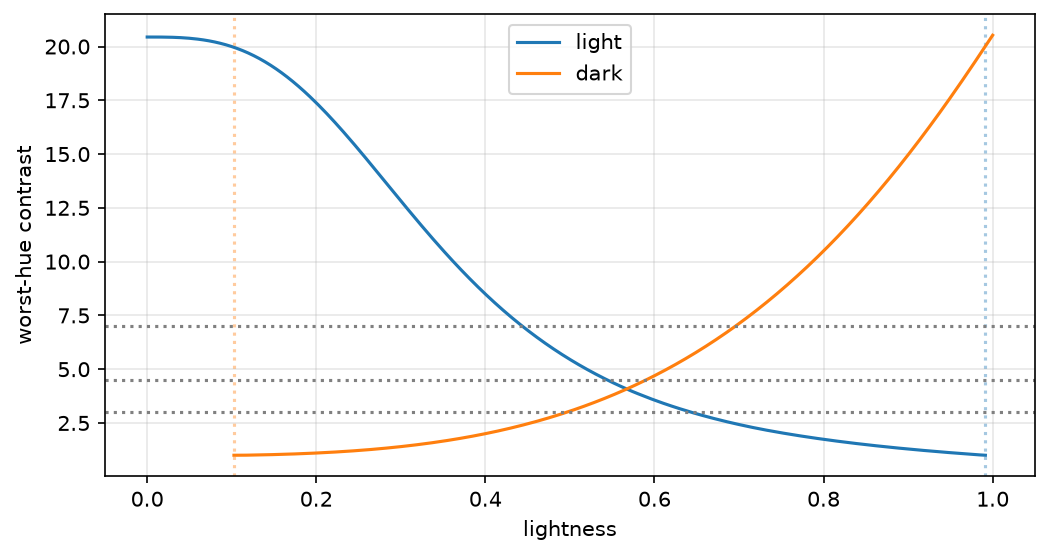

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for mode, baseL in base.items():
    edge = 0 if mode == 'light' else 1
    Ls = np.linspace(baseL, edge, 300)
    cs = [worst_contrast(L, capped(vivid_ceil, L, hgrid), baseL, capped(neutral_ceil, baseL, hgrid)) for L in Ls]
    ax.plot(Ls, cs, label=mode)
    ax.axvline(baseL, ls=':', color=ax.lines[-1].get_color(), alpha=.4)
for t in (3, 4.5, 7): ax.axhline(t, ls=':', color='gray')
ax.set(xlabel='lightness', ylabel='worst-hue contrast')
ax.legend(); ax.grid(alpha=.3)

Both curves are smooth and monotonic over their valid lightness ranges. Because worst-hue contrast crosses each target once as lightness moves away from the base, we can solve each rung's lightness with `solve_L`. The light and dark curves have different shapes, showing that dark-mode lightnesses cannot be obtained by inverting light mode and must be solved separately.

### Rungs with targets


To place a rung, we search outward from its background for the first lightness at which every job passes. For example, a `c=4.5` job passes once its worst-hue contrast against its background reaches `4.5`.

Each candidate rung is evaluated as an `(L, C)` pair: the trial lightness and the family chroma ceiling capped by the sRGB gamut at that lightness.

In [ ]:
def py_chroma(nm, L, h=hgrid):
    "Derived chroma of rung `nm` at lightness `L`: its family ceiling capped by the gamut"
    return capped(rungs[nm]['ceil'], L, h)

def LC(nm, L, chroma=py_chroma):
    "Rung `nm` at lightness `L`, as the (L, C) pair that `worst_contrast` and `worst_sep` take"
    return L, chroma(nm, L)

We'll pad targets by a small `margin` to account for 8-bit rounding.

In [ ]:
params['margin'] = 1.02

Let's first place two rungs by hand in light mode, starting from the base we derived earlier. First, `n-2`:

In [ ]:
lv = {'n-3': base['light']}
lv['n-2'] = solve_L(lambda L: worst_sep(*LC('n-2', L), *LC('n-3', lv['n-3'])), target=params['sep']*params['margin'], a=lv['n-3'], b=0)
{nm: round(L, 4) for nm, L in lv.items()}

{'n-3': 0.9914, 'n-2': 0.9506}

In [ ]:
test_close(worst_sep(*LC('n-2', lv['n-2']), *LC('n-3', lv['n-3'])), params['sep']*params['margin'], eps=1e-6)

A rung can have multiple jobs. Dividing each measurement by its target puts all jobs on a common scale where `1` means the job passes. A rung passes when its lowest job ratio reaches `1`. Starting from the most prominent background, a single root search finds the lightness where that minimum ratio equals `margin`. For example, the wash `v-3` must stay distinct from both `n-3` (page) and `n-2` (surface):

In [ ]:
def score(L): return min(
    worst_sep(*LC('v-3', L), *LC('n-3', lv['n-3'])) / params['sep'],
    worst_sep(*LC('v-3', L), *LC('n-2', lv['n-2'])) / params['sep'])

lv['v-3'] = solve_L(score, params['margin'], min(lv['n-3'], lv['n-2']), 0)
{nm: round(L, 4) for nm, L in lv.items()}

{'n-3': 0.9914, 'n-2': 0.9506, 'v-3': 0.913}

We now generalise this to any rung. Passing a `chroma` function into the solver lets us re-run the same optimisation against the chroma computed by CSS `oklch()`.

In [ ]:
def job_ratio(j, lc, bg, mode):
    "Worst-case measurement of job `j` divided by its target: at least 1 passes"
    if c := contrast_target(j, mode): return worst_contrast(*lc, *bg) / c
    return worst_sep(*lc, *bg) / j['d']

def solve_jobs(mode, nm, levels, chroma=py_chroma):
    "First lightness for `nm`, moving outward from its most prominent background, at which every targeted job passes, measured with `chroma`"
    jobs = [j for j in rungs[nm]['jobs'] if j['c'] or j['d']]
    bgs = {j['bg']: LC(j['bg'], levels[j['bg']], chroma) for j in jobs}
    start = (min if mode == 'light' else max)(L for L, _ in bgs.values())
    return solve_L(lambda L: min(job_ratio(j, LC(nm, L, chroma), bgs[j['bg']], mode) for j in jobs),
                   params['margin'], start, 0 if mode == 'light' else 1)

In [ ]:
for nm in ('n-2', 'v-3'): test_close(solve_jobs('light', nm, lv), lv[nm])

### Rungs without targets


Unpinned rungs are spaced geometrically by base contrast between their placed neighbours, because contrast is a ratio.

Place `n1` with the solver and fill in the gaps by hand:

In [ ]:
lv['n1'] = solve_jobs('light', 'n1', lv)
def cbase(nm, L): return worst_contrast(*LC(nm, L), *LC('n-3', lv['n-3']))

for nm, t in zip(('n-1', 'n'), np.geomspace(cbase('n-2', lv['n-2']), cbase('n1', lv['n1']), 4)[1:-1]):
    lv[nm] = solve_L(lambda L: cbase(nm, L), t, lv['n-3'], 0)
{nm: round(L, 4) for nm, L in lv.items()}

{'n-3': 0.9914,
 'n-2': 0.9506,
 'v-3': 0.913,
 'n1': 0.5247,
 'n-1': 0.7903,
 'n': 0.6503}

Each step should multiply the base contrast by the same factor:

In [ ]:
cs = np.array([cbase(nm, lv[nm]) for nm in ('n-2', 'n-1', 'n', 'n1')])
test_close(cs[1:]/cs[:-1], cs[1]/cs[0])

Again, generalise:

In [ ]:
def interp_unpinned(ladder, mode, levels, chroma=py_chroma):
    "Fill each run of unpinned rungs with log-spaced base contrasts between its placed neighbours"
    def cb(nm, L): return worst_contrast(*LC(nm, L, chroma), *LC('n-3', levels['n-3'], chroma))
    nms, edge = list(ladder), 0 if mode == 'light' else 1
    pins = [i for i, nm in enumerate(nms) if nm in levels]
    for a, b in zip(pins, pins[1:]):
        ts = np.geomspace(cb(nms[a], levels[nms[a]]), cb(nms[b], levels[nms[b]]), b-a+1)
        for nm, t in zip(nms[a+1:b], ts[1:-1]): levels[nm] = solve_L(lambda L: cb(nm, L), t, levels['n-3'], edge)

Because every target references an earlier rung, solving pinned rungs in declaration order resolves each background before it is needed. Interpolation then fills the unpinned rungs.

In [ ]:
def fit_ladders(mode, chroma=py_chroma):
    "Lightness of every rung in `mode`: the base, then pinned rungs in declaration order, then the rest by interpolation"
    levels = {'n-3': solve_L(lambda L: worst_pole_contrast(L, mode)[0], params['pole_contrast'])}
    for nm, r in rungs.items():
        if any(j['c'] or j['d'] for j in r['jobs']): levels[nm] = solve_jobs(mode, nm, levels, chroma)
    for lad in (neutral, vivid): interp_unpinned(lad, mode, levels, chroma)
    return {nm: levels[nm] for nm in rungs}

In [ ]:
levels = {mode: fit_ladders(mode) for mode in ('light', 'dark')}
test_close([levels['light'][nm] for nm in lv], list(lv.values()))
pd.DataFrame(levels).round(4).T

,n-3,n-2,n-1,n,n1,n2,v-3,v-2,v-1,v,v1,v2
light,0.9914,0.9506,0.7903,0.6503,0.5247,0.4217,0.9130,0.7453,0.6068,0.5109,0.4609,0.4111
dark,0.1026,0.1434,0.3385,0.4611,0.5812,0.7918,0.1825,0.3792,0.5094,0.7100,0.7553,0.8024


Next we verify three properties: every job holds at its worst hue, each ladder is monotonic in lightness, and every generated colour stays inside sRGB.

A rung solved to its exact target can drop slightly below target after rounding to 8-bit sRGB for display. Solving with `margin = 1.02` absorbs that rounding loss. We check each job on both exact and 8-bit rounded colours.

In [ ]:
def lum8(L, C):
    "Relative luminance after rounding to 8-bit sRGB"
    return srgb2lum(np.round(np.clip(lin2srgb(oklch2lin(L, C, hgrid)), 0, 1)*255)/255)

def worst_contrast8(L1, C1, L2, C2):
    "`worst_contrast` after rounding both colours to 8-bit sRGB"
    return contrast(lum8(L1, C1)[:,None], lum8(L2, C2)[None,:]).min()

In [ ]:
lc, bg = LC('n1', levels['light']['n1']), LC('n-2', levels['light']['n-2'])
worst_contrast(*lc, *bg), worst_contrast8(*lc, *bg)

(np.float64(4.59), np.float64(4.554402714979339))

8-bit rounding reduces contrast by under 1%, well within the 2% buffer from `margin`. We run the same check across all declared jobs:

In [ ]:
def rung_c(nm, mode): return py_chroma(nm, levels[mode][nm])

def failing_jobs(chroma=rung_c, tol=0, lightness=None):
    "Jobs that miss their target by more than `tol` under `chroma`, each with its worst measurement-to-target ratio"
    bad = []
    if lightness is None: lightness = levels
    for m in levels:
        for nm, r in rungs.items():
            for j in r['jobs']:
                if not (j['c'] or j['d']): continue
                lc, bg = (lightness[m][nm], chroma(nm, m)), (lightness[m][j['bg']], chroma(j['bg'], m))
                w = job_ratio(j, lc, bg, m)
                if c := contrast_target(j, m): w = min(w, worst_contrast8(*lc, *bg)/c)
                if w < 1 - tol: bad.append(dict(mode=m, rung=nm, job=j['desc'], ratio=round(w, 3)))
    return bad

In [ ]:
assert not failing_jobs(tol=1e-6)
for m, lvl in levels.items():
    sgn = -1 if m == 'light' else 1
    for lad in (neutral, vivid):
        nms = [lvl[nm] for nm in lad]
        assert (sgn*np.diff(nms) > 0).all()
        assert all(worst_sep(*LC(a, lvl[a]), *LC(b, lvl[b])) >= 1 for a, b in zip(lad, list(lad)[1:]))
    assert all(in_gamut(L, py_chroma(nm, L), hgrid).all() for nm, L in lvl.items())

We render light and dark swatch cards across five representative hues to inspect the palette visually:

In [ ]:
def rung_hex(nm, mode, h, chroma=rung_c):
    "Displayable hex of rung `nm` at context hue `h`, under chroma function `chroma`"
    return oklch2hex(levels[mode][nm], chroma(nm, mode)[h], h)

def card(*content, mode, h, lbl='', chroma=rung_c):
    "`content` (default: both ladders) on the `mode` page colour `n-3` at hue `h`, with text in body colour `n2`"
    if not content: content = [swatches([rung_hex(nm,mode,h,chroma) for nm in lad], list(lad)) for lad in (neutral, vivid)]
    return Div(Div(lbl, style='font-size:.75rem'), *content,
               style=f'background:{rung_hex("n-3",mode,h,chroma)};color:{rung_hex("n2",mode,h,chroma)};padding:1rem;border-radius:8px;display:flex;flex-direction:column;gap:6px')

In [ ]:
hues = dict(red=25, yellow=100, green=145, blue=260, magenta=330)

def ladder_cards(chroma=rung_c):
    "Light and dark cards for each named hue"
    return Div(*[card(mode=m, h=h, lbl=f'{nm} {h}°, {m}', chroma=chroma) for nm, h in hues.items() for m in ('light', 'dark')],
               style='display:grid;grid-template-columns:1fr 1fr;gap:8px')

ladder_cards()

<div style="display:grid;grid-template-columns:1fr 1fr;gap:8px"><div style="background:#fffbfb;color:#584a48;padding:1rem;border-radius:8px;display:flex;flex-direction:column;gap:6px"><div style="font-size:.75rem">red 25°, light</div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#fffbfb;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-3</div></div><div style="flex:1"><div style="background:#fceae8;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-2</div></div><div style="flex:1"><div style="background:#c7b6b4;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-1</div></div><div style="flex:1"><div style="background:#9b8b89;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n</div></div><div style="flex:1"><div style="background:#766664;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n1</div></div><div style="flex:1"><div style="background:#584a48;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n2</div></div></div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#fadad6;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-3</div></div><div style="flex:1"><div style="background:#f58982;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-2</div></div><div style="flex:1"><div style="background:#dc4645;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-1</div></div><div style="flex:1"><div style="background:#be1122;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v</div></div><div style="flex:1"><div style="background:#a80019;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v1</div></div><div style="flex:1"><div style="background:#900014;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v2</div></div></div></div><div style="background:#080202;color:#c8b7b5;padding:1rem;border-radius:8px;display:flex;flex-direction:column;gap:6px"><div style="font-size:.75rem">red 25°, dark</div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#080202;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-3</div></div><div style="flex:1"><div style="background:#110706;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-2</div></div><div style="flex:1"><div style="background:#413432;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-1</div></div><div style="flex:1"><div style="background:#635453;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n</div></div><div style="flex:1"><div style="background:#867675;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n1</div></div><div style="flex:1"><div style="background:#c8b7b5;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n2</div></div></div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#2b0002;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-3</div></div><div style="flex:1"><div style="background:#810010;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-2</div></div><div style="flex:1"><div style="background:#be1022;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-1</div></div><div style="flex:1"><div style="background:#f07871;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v</div></div><div style="flex:1"><div style="background:#f68e86;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:c

Next we emit CSS that lets the browser compute these colours from `--hue` and `--neutral-hue` at runtime.

## CSS Generation


In the stylesheet each rung is a `light-dark()` pair. The browser uses `--hue` for the vivid ladder and `--neutral-hue` for the neutral ladder. Lightness is the constant solved above, while chroma is the smaller of the rung's aesthetic ceiling and the sRGB gamut boundary at that lightness. We approximate that hue-dependent chroma with a CSS expression and re-verify every job against the emitted CSS values.

### Boundary approximation


When a rung's ceiling stays inside sRGB at every hue, the CSS can use that ceiling as a constant. Only rungs whose ceiling crosses the gamut boundary at some hue need a hue-dependent approximation. Below we compute the fraction of hues constrained by the gamut boundary for each rung:

In [ ]:
def ceiling(nm, mode): return rungs[nm]['ceil'](levels[mode][nm])

boundary_frac = pd.Series({(m, nm): (cmax(L, hgrid) < ceiling(nm, m)).mean()
                   for m in levels for nm, L in levels[m].items()}).sort_values(ascending=False)
gamut_constrained = list(boundary_frac[boundary_frac > 0].index)
boundary_frac.round(2)

light  n-3    0.93
dark   v-3    0.86
       v-2    0.84
light  v2     0.82
       v1     0.77
dark   v-1    0.64
light  v      0.64
       v-1    0.56
dark   v      0.27
light  v-2    0.14
dark   n-3    0.09
       v2     0.07
       v1     0.06
light  v-3    0.00
       n-2    0.00
dark   n-2    0.00
       n-1    0.00
       n      0.00
       n1     0.00
       n2     0.00
light  n2     0.00
       n1     0.00
       n      0.00
       n-1    0.00
dtype: float64

Because the capped gamut boundary is periodic in hue and CSS supports trigonometric functions, we can approximate it with a truncated Fourier series in `--hue`.

The approximation must never exceed the sRGB boundary (G2). Ordinary least squares penalises overshoot and undershoot equally. We iteratively double the weight on overshooting hues until the curve stays below the target everywhere, then subtract any remaining positive residual from the constant term.

In [ ]:
def harmonics(h, K):
    "Fourier design matrix over hues `h` in degrees: 1, cos kh, sin kh for k=1..K"
    hr = np.deg2rad(h)[:,None]*np.arange(1, K+1)
    return np.concatenate([np.ones((len(h),1)), np.cos(hr), np.sin(hr)], axis=1)

def fit_below(g, K, iters=40):
    "Coefficients of a `K`-harmonic fit that approaches `g` from below"
    X, w = harmonics(hgrid, K), np.ones_like(g)
    for _ in range(iters):
        sw = np.sqrt(w)[:,None]
        co = np.linalg.lstsq(X*sw, g*sw[:,0], rcond=None)[0]
        over = X@co > g
        if not over.any(): break
        w[over] *= 2
    co[0] -= max(0, (X@co - g).max())
    return co

def fit_rung(nm, mode, K):
    "Coefficients approximating rung `nm`'s derived chroma from below"
    return fit_below(rung_c(nm, mode), K)

The dark wash (`v-3`) is the most gamut-constrained vivid rung. The fit at various values of `K`:

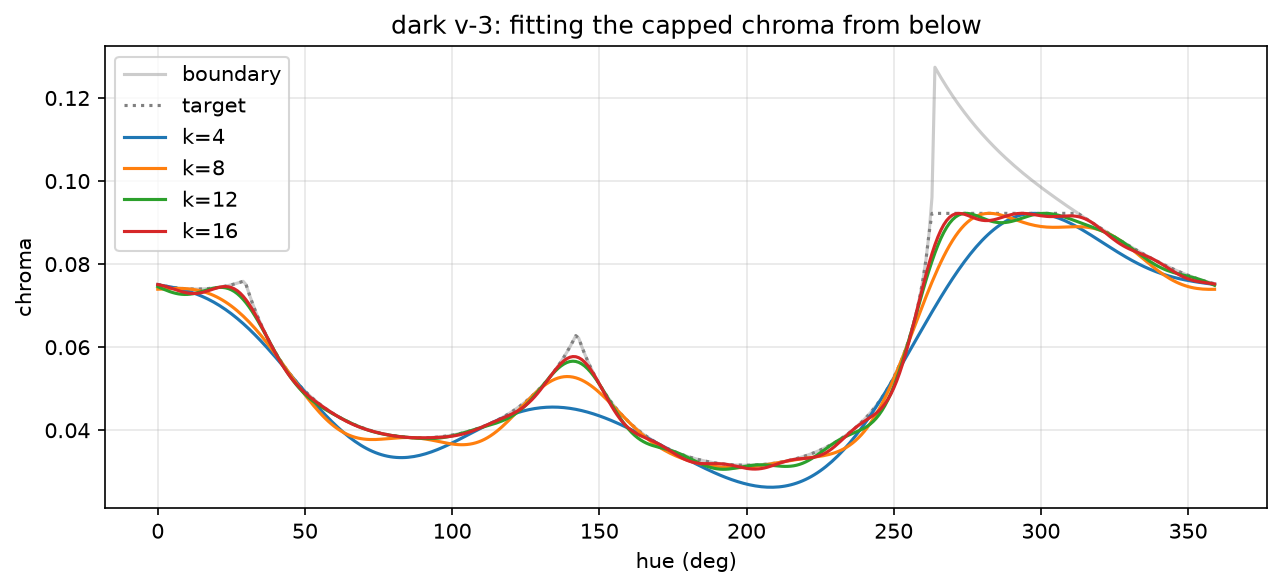

In [ ]:
def plot_fourier_fit(m, nm, ks=(4, 8, 12, 16)):
    "Plot gamut boundary, target chroma, and Fourier fits at harmonic counts `ks` for rung `nm` in mode `m`"
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(hgrid, cmax(levels[m][nm], hgrid), color='gray', alpha=.4, label='boundary')
    ax.plot(hgrid, rung_c(nm, m), ls=':', color='gray', label='target')
    for k in ks: ax.plot(hgrid, harmonics(hgrid, k)@fit_rung(nm, m, k), label=f'{k=}')
    ax.set(xlabel='hue (deg)', ylabel='chroma', title=f'{m} {nm}: fitting the capped chroma from below')
    ax.legend(); ax.grid(alpha=.3)

plot_fourier_fit('dark', 'v-3')

Dark mode's `v2` is far less gamut-constrained:

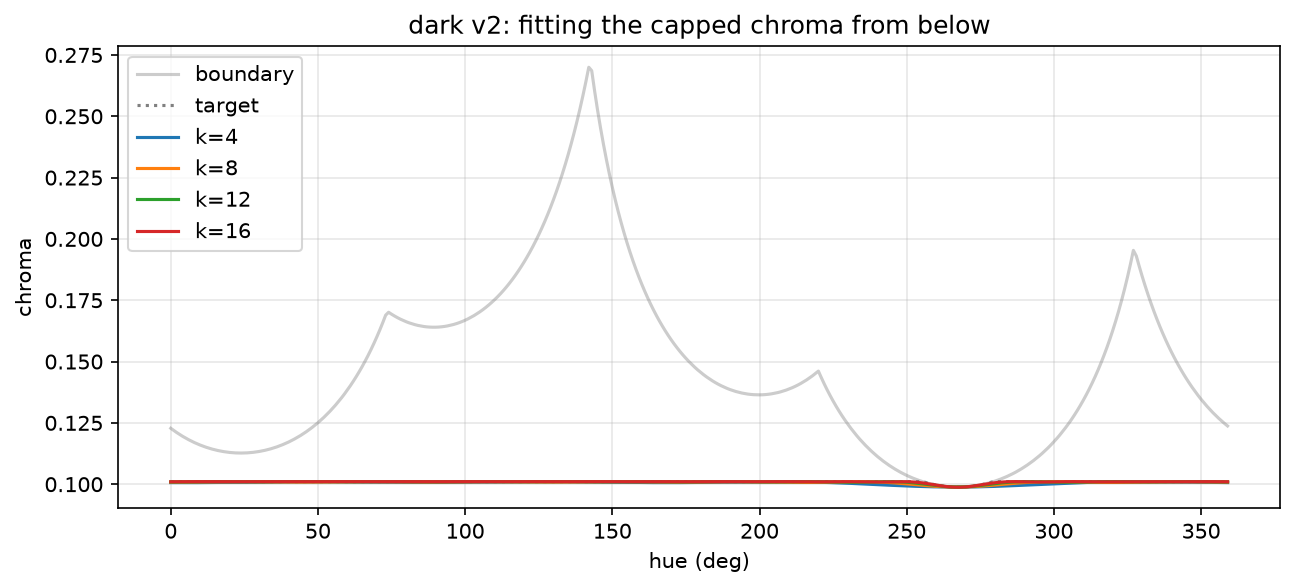

In [ ]:
plot_fourier_fit('dark', 'v2')

A large `K` is needed for heavily constrained rungs and unnecessary for flatter ones.

We measure retention as the minimum ratio of fitted chroma to derived chroma across all hues.

In [ ]:
def fit_c(nm, mode, K):
    "Chroma of the `K`-harmonic fit for rung `nm`, clipped to between 0 and its ceiling"
    return np.clip(harmonics(hgrid, K)@fit_rung(nm, mode, K), 0, ceiling(nm, mode))

def retention(nm, mode, K):
    "Fitted chroma as a fraction of derived, at the worst hue"
    return (fit_c(nm, mode, K)/rung_c(nm, mode)).min()

pd.DataFrame({K: [retention(nm, m, K) for m, nm in gamut_constrained] for K in (2, 4, 8, 12, 16)},
             index=pd.MultiIndex.from_tuples(gamut_constrained, names=['mode', 'rung'])).round(2)

2     4     8     12    16
mode  rung                              
light n-3   0.53  0.55  0.82  0.85  0.90
dark  v-3   0.62  0.72  0.82  0.87  0.89
      v-2   0.63  0.72  0.84  0.89  0.90
light v2    0.64  0.72  0.83  0.88  0.90
      v1    0.61  0.73  0.84  0.90  0.91
dark  v-1   0.59  0.73  0.84  0.90  0.92
light v     0.59  0.73  0.84  0.90  0.92
      v-1   0.63  0.81  0.90  0.94  0.95
dark  v     0.85  0.93  0.96  0.97  0.98
light v-2   0.96  0.96  0.98  0.99  0.99
dark  n-3   0.96  0.97  0.98  0.99  0.99
      v2    0.98  0.98  0.99  0.99  1.00
      v1    0.98  0.98  0.99  0.99  0.99

Four harmonics suffice for lightly constrained rows, with minimal gain past `K=12` anywhere. To avoid extra CSS terms on simple rungs without losing chroma on constrained ones, we choose `K` per rung:

In [ ]:
m, nm = 'light', 'v2'
L, h = levels[m][nm], (fit_c(nm, m, 12)/rung_c(nm, m)).argmin()
ks = (4, 8, 12, 16)
cs = [rung_c(nm, m)[h]] + [fit_c(nm, m, k)[h] for k in ks]
lbls = ['derived'] + [f'K={k} ({fit_c(nm,m,k)[h]/rung_c(nm,m)[h]:.2f})' for k in ks]
display(card(swatches([oklch2hex(L, c, h) for c in cs], lbls), mode=m, h=h, lbl=f'{m} {nm} {h}°'))

<div style="background:#fbfcff;color:#484e59;padding:1rem;border-radius:8px;display:flex;flex-direction:column;gap:6px"><div style="font-size:.75rem">light v2 262°</div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#003caf;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">derived</div></div><div style="flex:1"><div style="background:#1b4497;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">K=4 (0.75)</div></div><div style="flex:1"><div style="background:#13429f;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">K=8 (0.83)</div></div><div style="flex:1"><div style="background:#0e41a4;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">K=12 (0.88)</div></div><div style="flex:1"><div style="background:#0c40a5;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">K=16 (0.90)</div></div></div></div>

At `K=4` (75% retention) the colour looks noticeably muddier, whereas from `K=8` upward the difference is hard to see. We set the retention threshold to `0.85`.

In [ ]:
params['retention'] = .85

def solve_K(nm, mode, Kmax=16):
    "Smallest K retaining `params['retention']` of rung `nm`'s derived chroma"
    return next(K for K in range(1, Kmax+1) if retention(nm, mode, K) >= params['retention'])

Ks = {(m, nm): solve_K(nm, m) for m, nm in gamut_constrained}
fits = {(m, nm): fit_rung(nm, m, K) for (m, nm), K in Ks.items()}
pd.Series(Ks)

light  n-3    12
dark   v-3    11
       v-2     9
light  v2      9
       v1      9
dark   v-1     9
light  v       9
       v-1     6
dark   v       2
light  v-2     1
dark   n-3     1
       v2      1
       v1      1
dtype: int64

### Assembly


Every rung now has a solved lightness and a CSS-computable chroma function to pack into the stylesheet.

Writing the Fourier series in amplitude-phase form halves the term count, turning `a cos(kh) + b sin(kh)` into `R cos(kh - φ)`. We round each coefficient and drop terms with amplitude below `1e-5`. Subtracting dropped amplitudes and rounding overshoot from the constant term keeps the series below the target everywhere.


In [ ]:
def floor5(x):
    "Round down to 5 decimals, keeping one-sided approximations one-sided"
    return float(np.floor(x*1e5)/1e5)

def eval_terms(c0, terms, h):
    "The chroma series `c0 + Σ R cos(kh - φ)` at hues `h`"
    hr = np.deg2rad(np.asarray(h, float))
    return c0 + sum((R*np.cos(k*hr - np.deg2rad(phi)) for k, R, phi in terms), np.zeros_like(hr))

def round_fit(co, g):
    "Amplitude-phase form of `co`, rounded and pruned, kept one-sided under target `g`"
    K = (len(co)-1)//2
    c0, terms = co[0], []
    for k in range(1, K+1):
        R = np.hypot(co[k], co[K+k])
        if R < 1e-5: c0 -= R; continue
        terms.append((k, round(float(R), 5), round(float(np.rad2deg(np.arctan2(co[K+k], co[k]))) % 360, 2)))
    c0 -= max(0, (eval_terms(c0, terms, hgrid) - g).max())
    return floor5(c0), terms

Collect the rounded lightness, ceiling, and harmonic terms for each rung:


In [ ]:
ship = {}
for m in levels:
    for nm, L in levels[m].items():
        s = dict(L=round(L, 4), T=floor5(ceiling(nm, m)))
        if (m, nm) in fits: s['c0'], s['terms'] = round_fit(fits[(m, nm)], py_chroma(nm, s['L']))
        else: s['c0'], s['terms'] = s['T'], []
        ship[(m, nm)] = s

def css_chroma(nm, mode, h=hgrid):
    "Chroma the emitted CSS computes for rung `nm`: the rounded series, clamped to the rounded ceiling"
    s = ship[(mode, nm)]
    return np.clip(eval_terms(s['c0'], s['terms'], np.atleast_1d(h)), 0, s['T'])

For an unconstrained rung, `chroma_expr` emits a single constant. For a gamut-constrained rung, it emits `clamp(0, series, ceiling)` using `--neutral-hue` or `--hue` in each cosine term. `ladder_css` formats every rung as a `light-dark()` custom property with its job descriptions in a trailing comment.

In [ ]:
def chroma_expr(s, hue):
    "CSS for the chroma: a constant, or the clamped series derived from `hue`"
    if not s['terms']: return f"{s['T']}"
    series = f"{s['c0']}" + ''.join(f" + {R}*cos(({k}*{hue} - {phi})*1deg)" for k, R, phi in s['terms'])
    return f"clamp(0, {series}, {s['T']})"

def color_css(nm, mode):
    "The rung's CSS colour, derived from its own ladder's hue"
    s = ship[(mode, nm)]
    hue = 'var(--neutral-hue)' if nm in neutral else 'var(--hue)'
    return f"oklch({s['L']} {chroma_expr(s, hue)} {hue})"

def ladder_css():
    "Every rung as a light-dark pair, with its jobs in the trailing comment"
    def tok(nm): return f"--{nm}: light-dark({color_css(nm, 'light')}, {color_css(nm, 'dark')});"
    def jobs(nm): return '; '.join(j['desc'] for j in rungs[nm]['jobs'])
    return '\n'.join(f"{tok(nm)} /* {jobs(nm)} */" for nm in rungs) + '\n'

In [ ]:
print(color_css('n1', 'light'))
print(color_css('v-3', 'dark'))
css = ladder_css()
f'{len(css.splitlines())} tokens, {len(css):,} chars'

oklch(0.5247 0.02 var(--neutral-hue))
oklch(0.1825 clamp(0, 0.05701 + 0.02563*cos((1*var(--hue) - 325.45)*1deg) + 0.01252*cos((2*var(--hue) - 263.8)*1deg) + 0.00819*cos((3*var(--hue) - 96.1)*1deg) + 0.00256*cos((4*var(--hue) - 85.33)*1deg) + 0.0017*cos((5*var(--hue) - 319.1)*1deg) + 0.0034*cos((6*var(--hue) - 157.26)*1deg) + 0.00073*cos((7*var(--hue) - 138.05)*1deg) + 0.00112*cos((8*var(--hue) - 2.43)*1deg) + 0.00177*cos((9*var(--hue) - 237.19)*1deg) + 0.00037*cos((10*var(--hue) - 228.33)*1deg) + 0.00064*cos((11*var(--hue) - 69.15)*1deg), 0.09221) var(--hue))


'12 tokens, 5,425 chars'

Now we re-verify every declared job using `css_chroma` and the rounded lightnesses. Both the one-sided Fourier fit and lightness rounding reduce chroma slightly, staying within the `margin` buffer. If any job fails here, re-run `fit_ladders` with `css_chroma`.

In [ ]:
shipped_lightness = {mode: {nm: ship[(mode,nm)]['L'] for nm in rungs} for mode in levels}
assert not failing_jobs(css_chroma, lightness=shipped_lightness)
assert all(in_gamut(ship[(m,nm)]['L'], css_chroma(nm, m), hgrid).all() for m in levels for nm in levels[m])

Here are the ladder cards again, this time from the CSS's numbers. They should be hard to tell apart from the derived cards:

In [ ]:
ladder_cards(css_chroma)

<div style="display:grid;grid-template-columns:1fr 1fr;gap:8px"><div style="background:#fffbfb;color:#584a48;padding:1rem;border-radius:8px;display:flex;flex-direction:column;gap:6px"><div style="font-size:.75rem">red 25°, light</div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#fffbfb;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-3</div></div><div style="flex:1"><div style="background:#fceae8;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-2</div></div><div style="flex:1"><div style="background:#c7b6b4;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-1</div></div><div style="flex:1"><div style="background:#9b8b89;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n</div></div><div style="flex:1"><div style="background:#766664;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n1</div></div><div style="flex:1"><div style="background:#584a48;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n2</div></div></div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#fadad6;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-3</div></div><div style="flex:1"><div style="background:#f58982;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-2</div></div><div style="flex:1"><div style="background:#db4745;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-1</div></div><div style="flex:1"><div style="background:#bd1724;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v</div></div><div style="flex:1"><div style="background:#a60c1c;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v1</div></div><div style="flex:1"><div style="background:#8e0917;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v2</div></div></div></div><div style="background:#080202;color:#c8b7b5;padding:1rem;border-radius:8px;display:flex;flex-direction:column;gap:6px"><div style="font-size:.75rem">red 25°, dark</div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#080202;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-3</div></div><div style="flex:1"><div style="background:#110706;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-2</div></div><div style="flex:1"><div style="background:#413432;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n-1</div></div><div style="flex:1"><div style="background:#635453;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n</div></div><div style="flex:1"><div style="background:#867675;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n1</div></div><div style="flex:1"><div style="background:#c8b7b5;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">n2</div></div></div><div style="display:flex;gap:4px"><div style="flex:1"><div style="background:#2b0002;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-3</div></div><div style="flex:1"><div style="background:#7f0713;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-2</div></div><div style="flex:1"><div style="background:#bc1624;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v-1</div></div><div style="flex:1"><div style="background:#ed7b74;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:center">v</div></div><div style="flex:1"><div style="background:#f58e87;height:3rem;border-radius:4px"></div><div style="font-size:0.7rem;text-align:c

## Demo


Below is a minimal stylesheet using the generated ladder tokens to style a card:

In [ ]:
from answerui.preview import preview
from fasthtml.common import Article, H3, P, Em, A, Hr, Button, to_xml

def demo(*items, css): return preview(to_xml(*items), css=css, height='13rem')

In [ ]:
demo_css = 'body, article{' + ladder_css() + '''}
body{--hue:260;--neutral-hue:260;color-scheme:light;background:var(--n-3);color:var(--n2);margin:0;padding:1.5rem;font-family:system-ui}
article{background:var(--n-2);border:1px solid var(--n-1);border-radius:6px;padding:1rem;max-width:18rem}
a{color:var(--v)}
hr{border:none;border-top:1px solid var(--n-1)}
button{background:var(--v);color:var(--n-3);border:none;border-radius:6px;padding:.5rem 1rem;
  &:hover{background:var(--v1)}
  &[secondary]{background:var(--v-3);color:var(--v2);border:1px solid var(--v-1)}
}
'''

def payment_card(**kw):
    return Article(
        H3('Payment method'),
        P('Your card ending in ', Em('4242'), ' expires soon. ', A('See all cards', href='#'), '.'),
        Hr(),
        Button('Update card'), ' ', Button('Remind me later', secondary=True),
        **kw)

demo(payment_card(), css=demo_css)

```html
<article>
  <h3>Payment method</h3>
  <p>
Your card ending in <em>4242</em> expires soon. <a href="#">See all cards</a>.  </p>
<hr><button>Update card</button> <button secondary>Remind me later</button></article>

```

Overriding `--hue` for a danger state changes links and buttons while leaving the card surface and body text in the cool neutral ramp. Override `--neutral-hue` as well to tint the neutral ramp to match. Because the browser evaluates CSS custom property formulas on the declaring element before inheritance, `palette.css` redeclares the ladder tokens on `:root`, `[ui]`, `[ui-tone]`, and `[prose] mark`.

In [ ]:
demo_css += 'article[danger]{--hue:25}'
demo(payment_card(danger=True), css=demo_css)

```html
<article danger>
  <h3>Payment method</h3>
  <p>
Your card ending in <em>4242</em> expires soon. <a href="#">See all cards</a>.  </p>
<hr><button>Update card</button> <button secondary>Remind me later</button></article>

```

Because each token is a `light-dark()` pair, changing `color-scheme` switches the page between light and dark colours.

In [ ]:
demo(payment_card(), css=demo_css + 'body{color-scheme:dark}')

```html
<article>
  <h3>Payment method</h3>
  <p>
Your card ending in <em>4242</em> expires soon. <a href="#">See all cards</a>.  </p>
<hr><button>Update card</button> <button secondary>Remind me later</button></article>

```

## Shipping


`palette_css()` writes the generated CSS fragment to `nbs/palette.css`, which `#| asset_include styles.css palette.css` folds into the shared stylesheet used by HTML previews, Svelte, and Python. Rerun this notebook after changing any palette target to update the fitted coefficients in `nbs/palette.css`.

Inside `@layer tokens` and `@scope (:root, [ui]) to ([unstyle])`, `palette.css` defines:

- Root defaults: `color-scheme: light dark`, `--hue: 260`, `--neutral-hue: 260`, `--hue-danger: 25`, `--hue-warning: 75`, `--hue-success: 145`, and `--hue-info: 230`.
- Theme overrides: `[ui-theme=system]`, `[ui-theme=light]`, and `[ui-theme=dark]`.
- Tone overrides: `[ui-tone=danger]`, `[ui-tone=warning]` (also applied to `[prose] mark`), `[ui-tone=success]`, `[ui-tone=info]`, and `[ui-tone=neutral]` (which remaps `--v-3` through `--v2` to neutral rungs `--n-2` through `--n2`).
- Semantic tokens on `:root`, `[ui]`, `[ui-tone]`, and `[prose] mark`: `--color-text` (`--n2`), `--color-muted` (`--n1`), `--color-background` (`--n-3`), `--color-surface` (`--n-2`), `--color-border` (`--n-1`), `--color-accent` (`--v`), `--color-on-accent` (`--n-3`), and `--ring` (`2px solid var(--v-1)`).

Because CSS evaluates custom-property formulas on the declaring element before inheritance, changing `--hue` on an ordinary descendant does not recompute `--v-3` through `--v2` or `--color-accent`. For standard tones, set `ui-tone`. When an element overrides `--hue` dynamically from a custom CSS state rule (for example, switching a button's hue while `[aria-busy="true"]` or `.htmx-request` is active), add `ui` (`ui=True` in FastHTML) on that element so the ladder recomputes whenever `--hue` changes; component rules in `@layer components` override `[ui]`'s base rules in `@layer base`.

In [ ]:
def palette_css():
    return """
@layer tokens {
  @scope (:root, [ui]) to ([unstyle]) {
    :where(:scope):root {
      color-scheme: light dark;
      --hue: 260; --neutral-hue: 260;
      --hue-danger: 25; --hue-warning: 75; --hue-success: 145; --hue-info: 230;
    }
    :where(:scope, *) {
      &[ui-theme=system] { color-scheme: light dark; }
      &[ui-theme=light] { color-scheme: light; }
      &[ui-theme=dark] { color-scheme: dark; }
      &[ui-tone=danger] { --hue: var(--hue-danger); }
      &[ui-tone=warning] { --hue: var(--hue-warning); }
      &[ui-tone=success] { --hue: var(--hue-success); }
      &[ui-tone=info] { --hue: var(--hue-info); }
    }
    [prose] mark { --hue: var(--hue-warning); }

    :where(:scope):is(:root, [ui]), :where(:scope, *)[ui-tone], [prose] mark {
""" + indent(ladder_css().rstrip(), '      ') + """
      --color-text: var(--n2); --color-muted: var(--n1);
      --color-background: var(--n-3); --color-surface: var(--n-2); --color-border: var(--n-1);
      --color-accent: var(--v); --color-on-accent: var(--n-3);
      --ring: 2px solid var(--v-1);
    }
    :where(:scope, *)[ui-tone=neutral] {
      --v-3: var(--n-2); --v-2: var(--n-1); --v-1: var(--n); --v: var(--n1); --v1: var(--n2); --v2: var(--n2);
    }
  }
}
""".rstrip() + '\n'

asset = get_config().nbs_path/'palette.css'
css = palette_css().lstrip()
if not asset.exists() or asset.read_text() != css: asset.write_text(css)

In [ ]:
#| hide
#| asset_include styles.css palette.css
pass